# Descriptive Analytics

Before we start with the descriptive analysis tasks, let's take another look at certain features in the data set that may be important for the tasks (e.g. the number of records by site).

## General Descriptions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data_charge = pd.read_pickle("../data/data_charge_prep.pkl")

In [3]:
# Split the DataFrame according to the two sites
site1 = data_charge[data_charge["siteID"] == 1]
site2 = data_charge[data_charge["siteID"] == 2]

# Print the start and end of the timeframes
print(f"Site 1 Timespan: {site1.connectionTime.min()} - {site1.disconnectTime.max()}")
print(f"Site 2 Timespan: {site2.connectionTime.min()} - {site2.disconnectTime.max()}")
print("")

# Get the number of stations for each site
print(f"Number of stations for Site 1: {site1.stationID.nunique()}")
print(f"Number of stations for Site 2: {site2.stationID.nunique()}")

Site 1 Timespan: 2018-09-05 03:04:13+00:00 - 2021-09-14 06:46:28+00:00
Site 2 Timespan: 2018-04-25 05:45:10+00:00 - 2021-09-13 19:05:10+00:00

Number of stations for Site 1: 52
Number of stations for Site 2: 55


In [4]:
print(f"Samples for site 1: {len(data_charge[data_charge['siteID']==1])}")
print(f"Samples for site 2: {len(data_charge[data_charge['siteID']==2])}")

Samples for site 1: 32831
Samples for site 2: 31007


 Note: We have more samples for site 1, than for site 2. Therefore, we have to normalize our data, when comparing those two sites.

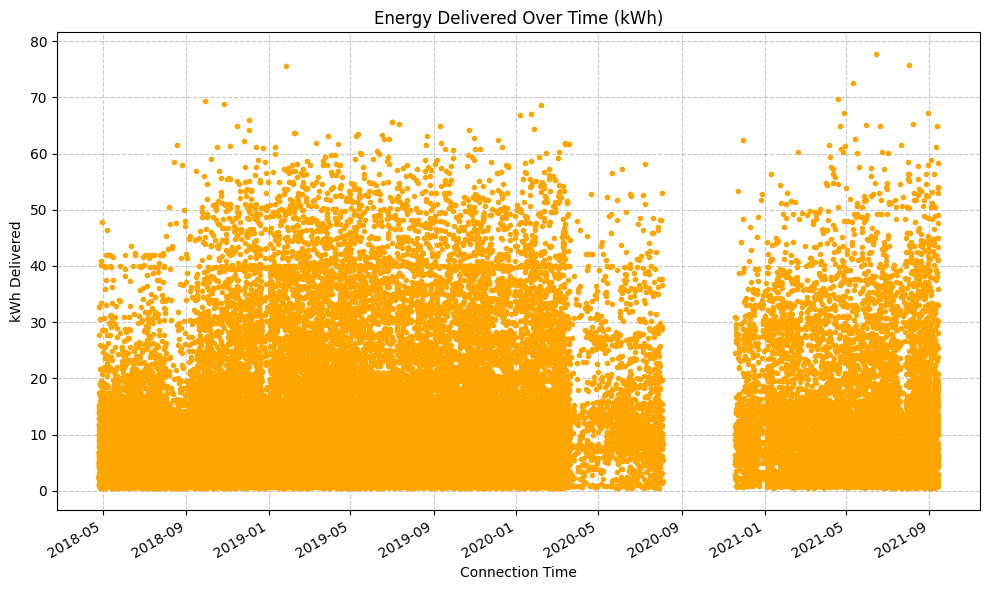

In [5]:
plt.figure(figsize=(10, 6))
data_charge.set_index("connectionTime").kWhDelivered.plot(style=".", color="orange")
plt.xlabel("Connection Time")
plt.ylabel("kWh Delivered")
plt.title("Energy Delivered Over Time (kWh)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

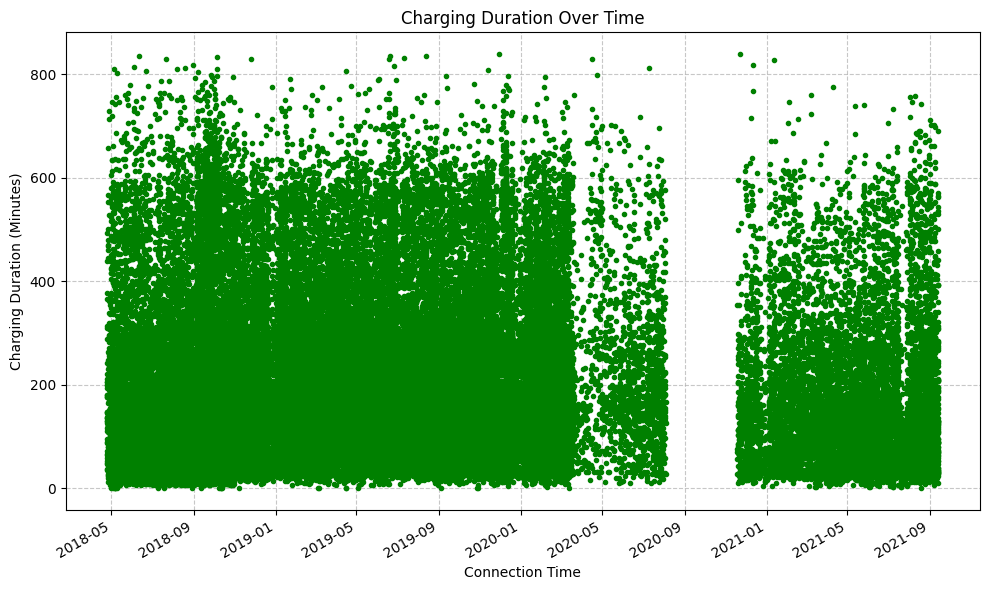

In [6]:
plt.figure(figsize=(10, 6))
data_charge.set_index("connectionTime").chargingDurationMin.plot(style=".", color="green")
plt.xlabel("Connection Time")
plt.ylabel("Charging Duration (Minutes)")
plt.title("Charging Duration Over Time")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

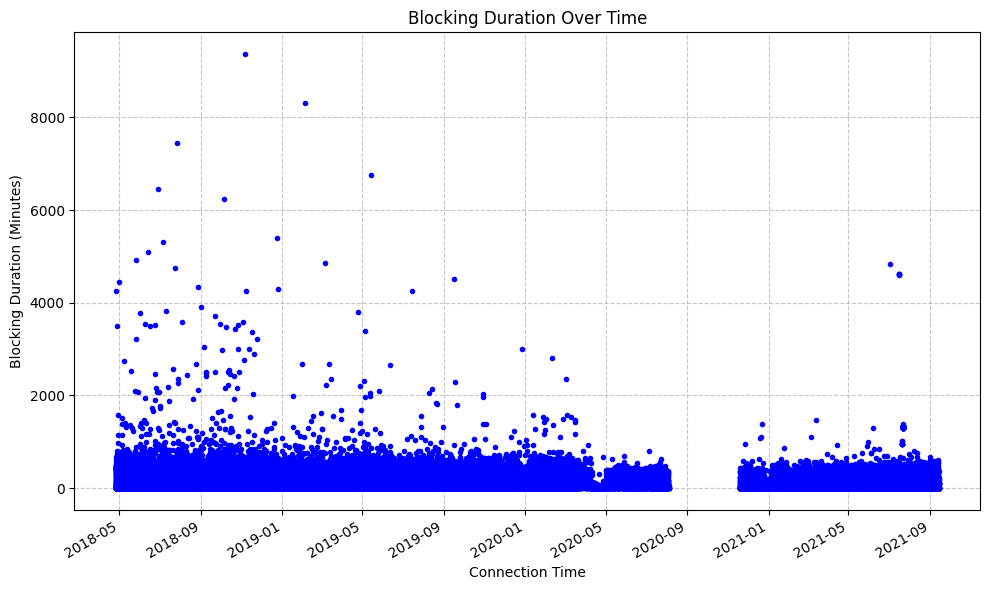

In [7]:
plt.figure(figsize=(10, 6))
data_charge.set_index("connectionTime").blockingDurationMin.plot(style=".", color="blue")
plt.xlabel("Connection Time")
plt.ylabel("Blocking Duration (Minutes)")
plt.title("Blocking Duration Over Time")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Note: There is a time gap in the dataset. Important information if we work for example with seasonal patterns since there is an unequal amount of months for each season.

## Temporal Patterns
 **Task**: Demonstrate how the number of charging events varies during the day, the week, and between seasons. What patterns can you observe, and how do you explain them?

### Pattern during the day

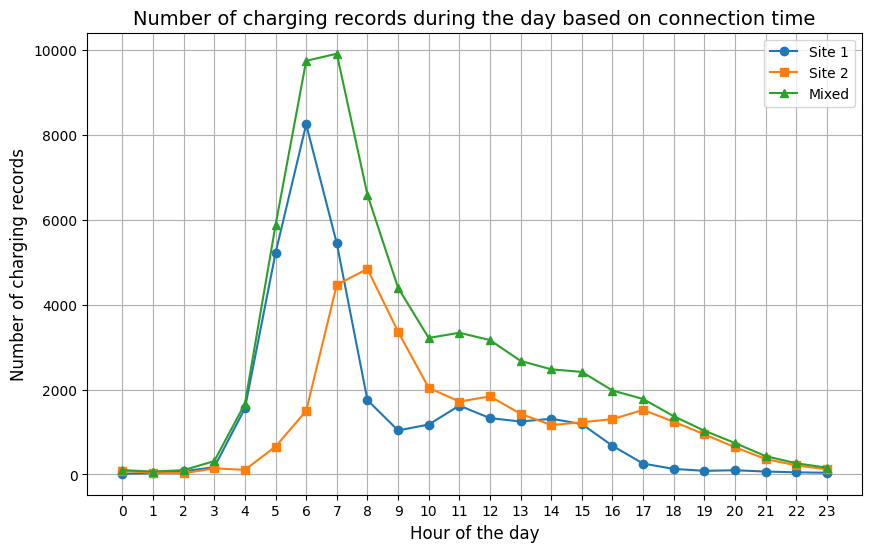

In [8]:
data_charge["hour"] = data_charge["connectionTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day based on connection time", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

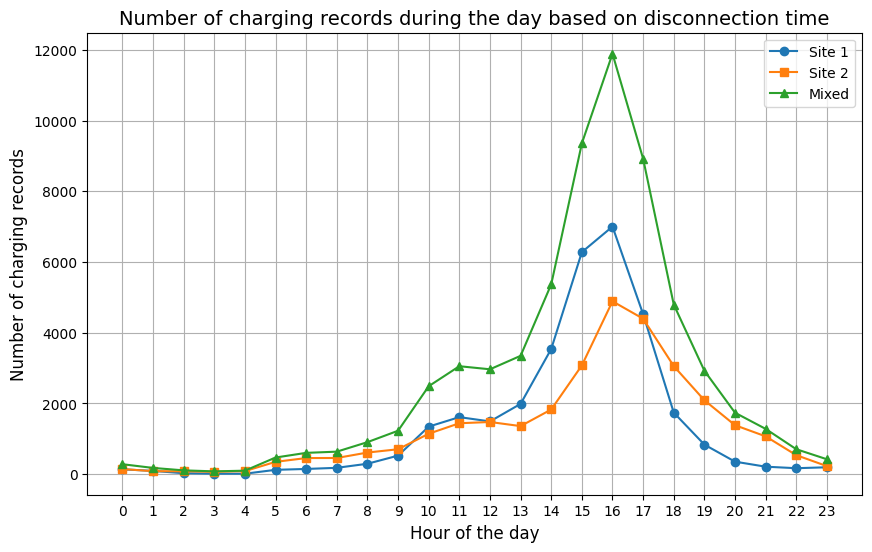

In [9]:
# Disconnect Count
data_charge["hour"] = data_charge["disconnectTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day based on disconnection time", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

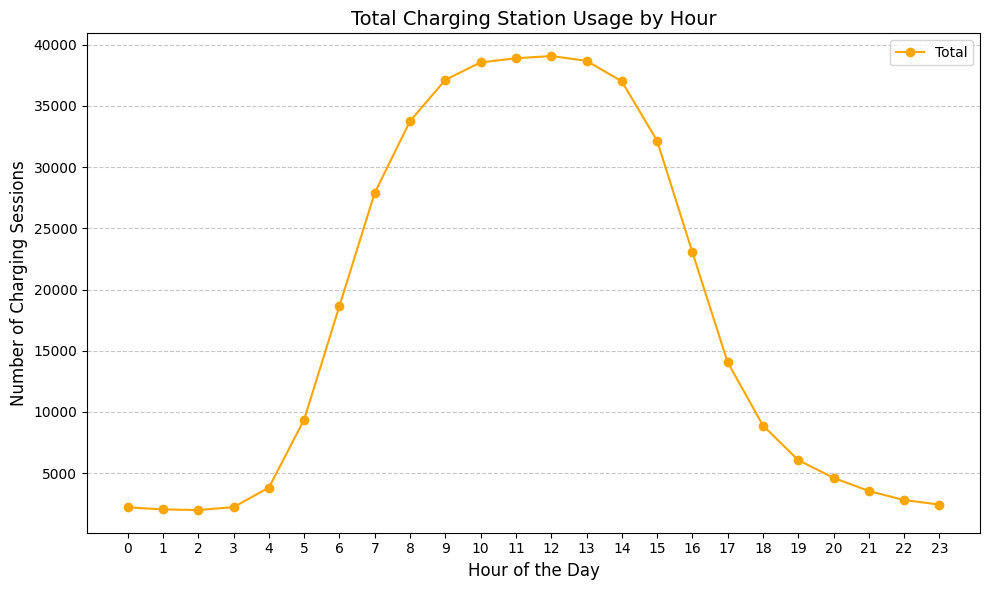

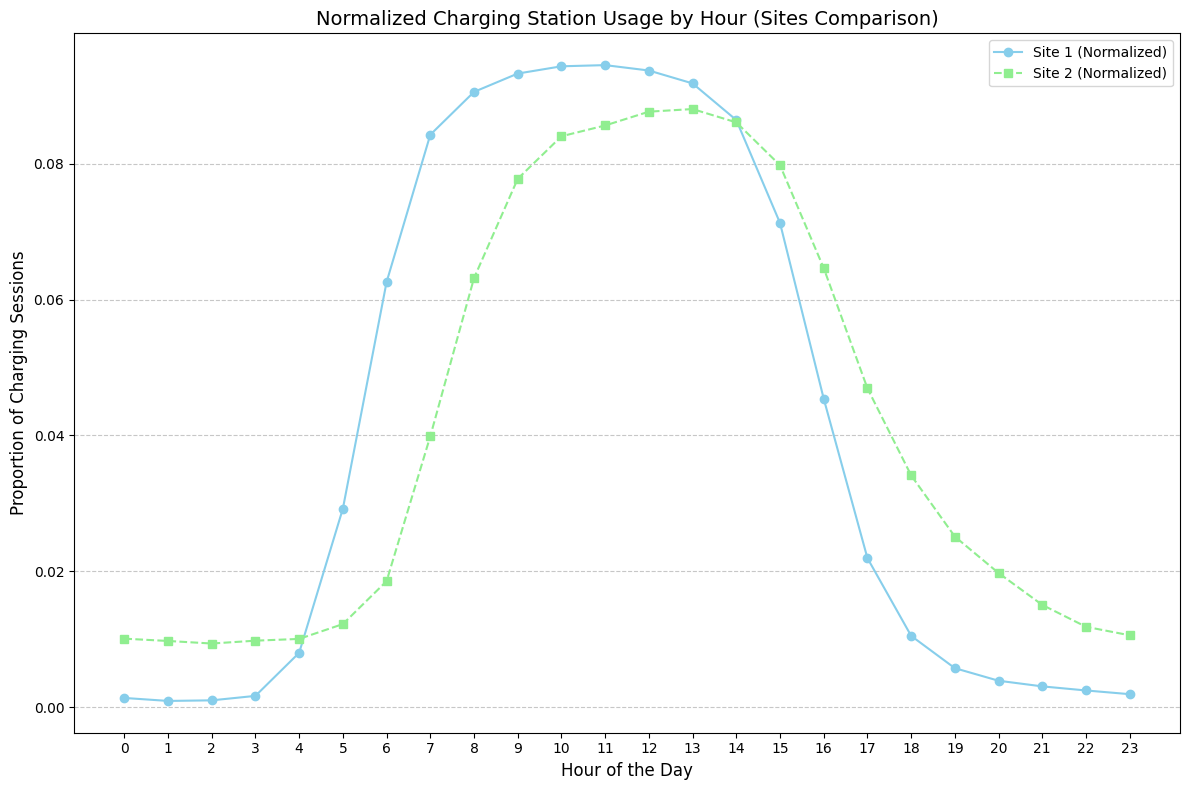

In [10]:
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge["disconnectTime"] = pd.to_datetime(data_charge["disconnectTime"])

def get_active_hours(row):
    active_hours = pd.date_range(row["connectionTime"], row["disconnectTime"], freq="H").hour
    return active_hours

data_charge["active_hours"] = data_charge.apply(get_active_hours, axis=1)

active_hours_flat = [hour for hours in data_charge["active_hours"] for hour in hours]
df_active_hours = pd.DataFrame(active_hours_flat, columns=["Hour"])
usage_by_hour = df_active_hours.groupby("Hour").size()

data_charge_site_1 = data_charge[data_charge["siteID"] == 1]
data_charge_site_2 = data_charge[data_charge["siteID"] == 2]

active_hours_site_1 = [hour for hours in data_charge_site_1["active_hours"] for hour in hours]
active_hours_site_2 = [hour for hours in data_charge_site_2["active_hours"] for hour in hours]

df_active_hours_site_1 = pd.DataFrame(active_hours_site_1, columns=["Hour"])
df_active_hours_site_2 = pd.DataFrame(active_hours_site_2, columns=["Hour"])

usage_by_hour_site_1 = df_active_hours_site_1.groupby("Hour").size()
usage_by_hour_site_2 = df_active_hours_site_2.groupby("Hour").size()

total_site_1 = usage_by_hour_site_1.sum()
total_site_2 = usage_by_hour_site_2.sum()

normalized_usage_site_1 = usage_by_hour_site_1 / total_site_1
normalized_usage_site_2 = usage_by_hour_site_2 / total_site_2

hours = list(range(24))  

plt.figure(figsize=(10, 6))
plt.plot(
    hours,
    usage_by_hour.reindex(hours, fill_value=0),
    label="Total",
    color="orange",
    marker="o",
    linestyle="-",
)
plt.title("Total Charging Station Usage by Hour", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(hours)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/hour_total_line.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 8))
plt.plot(
    hours,
    normalized_usage_site_1.reindex(hours, fill_value=0),
    label="Site 1 (Normalized)",
    color="skyblue",
    marker="o",
    linestyle="-",
)
plt.plot(
    hours,
    normalized_usage_site_2.reindex(hours, fill_value=0),
    label="Site 2 (Normalized)",
    color="lightgreen",
    marker="s",
    linestyle="--",
)
plt.title("Normalized Charging Station Usage by Hour (Sites Comparison)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Proportion of Charging Sessions", fontsize=12)
plt.xticks(hours)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/hour_sites_comparison_line.png", dpi=300, bbox_inches="tight")
plt.show()


**Daily observed patterns and explaination**
The use of the charging stations shows clear patterns that correspond to the daily routines of the users. During the night and early morning hours (12 a.m. to 4 a.m.), activity is very low, as vehicles are generally not used at this time. From 5 a.m. onwards, the number of charging processes increases significantly, indicating that users have driven somewhere (e.g. work) and parked and connected their car there.
The peak time is between 10 a.m. and 2 p.m., as all users are active until then. After 3 o'clock in the afternoon, activity decreases continuously, as many vehicles are already charged at this time or have completed their daily journeys. In the evening hours (from 8 a.m.), activity remains low, as charging tends to take place during the day.

The differences between the two sites are discussed later on.


### Pattern during the week

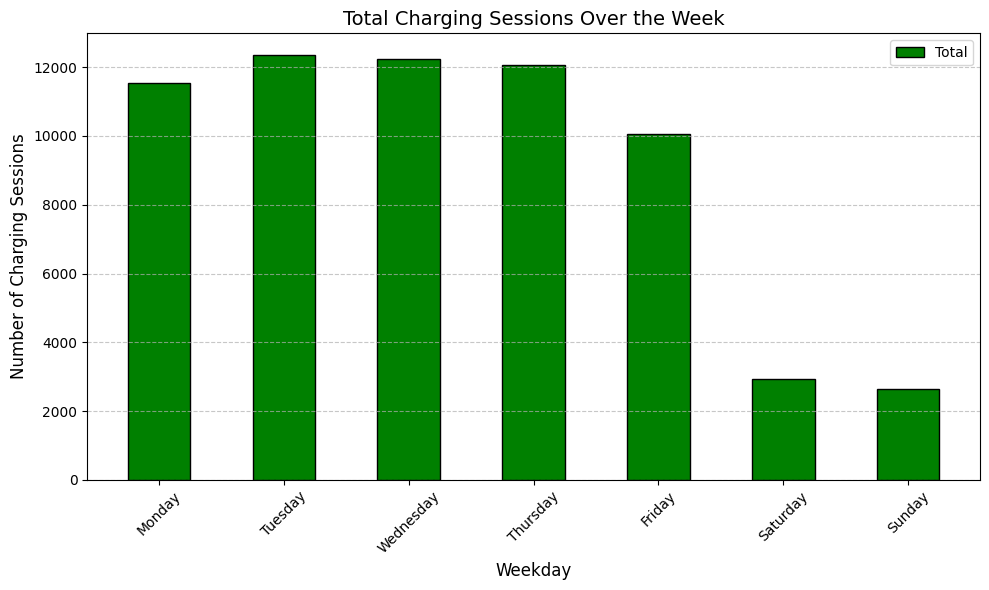

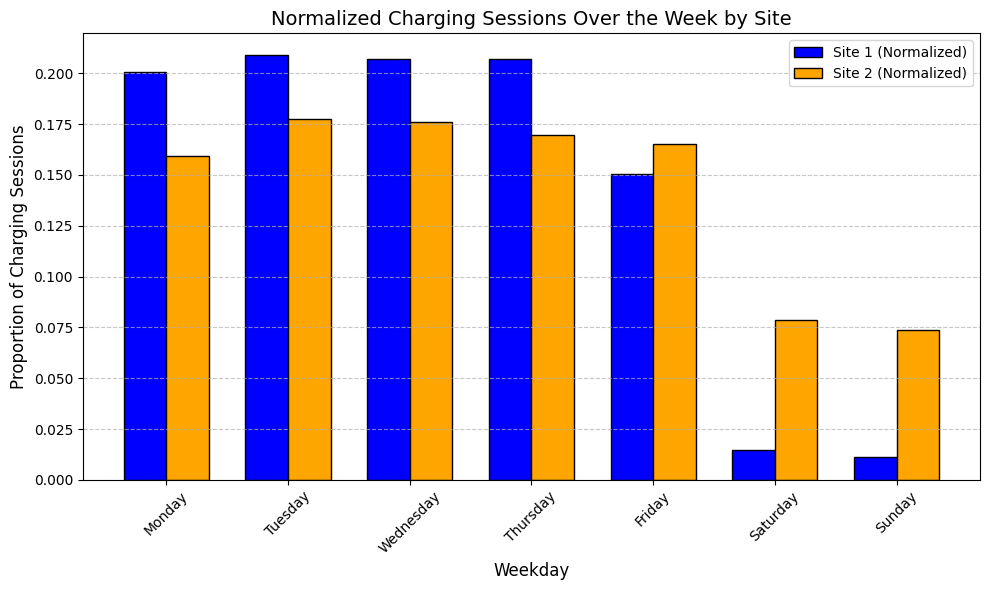

In [11]:
data_charge["weekday"] = data_charge["connectionTime"].dt.dayofweek

charging_by_weekday_site1 = (
    data_charge[data_charge["siteID"] == 1]["weekday"].value_counts().sort_index()
)
charging_by_weekday_site2 = (
    data_charge[data_charge["siteID"] == 2]["weekday"].value_counts().sort_index()
)
charging_by_weekday_total = data_charge["weekday"].value_counts().sort_index()

site1_total = charging_by_weekday_site1.sum()
site2_total = charging_by_weekday_site2.sum()

normalized_site1 = charging_by_weekday_site1 / site1_total
normalized_site2 = charging_by_weekday_site2 / site2_total

weekday_labels = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_indices = list(range(7))

plt.figure(figsize=(10, 6))
plt.bar(
    weekday_indices,
    charging_by_weekday_total,
    width=0.5,
    label="Total",
    color="green",
    edgecolor="black",
)
plt.title("Total Charging Sessions Over the Week", fontsize=14)
plt.xlabel("Weekday", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(weekday_indices, weekday_labels, rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/week_total.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 6))
bar_width = 0.35
plt.bar(
    [i - bar_width / 2 for i in weekday_indices],
    normalized_site1,
    width=bar_width,
    label="Site 1 (Normalized)",
    color="blue",
    edgecolor="black",
)
plt.bar(
    [i + bar_width / 2 for i in weekday_indices],
    normalized_site2,
    width=bar_width,
    label="Site 2 (Normalized)",
    color="orange",
    edgecolor="black",
)
plt.title("Normalized Charging Sessions Over the Week by Site", fontsize=14)
plt.xlabel("Weekday", fontsize=12)
plt.ylabel("Proportion of Charging Sessions", fontsize=12)
plt.xticks(weekday_indices, weekday_labels, rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/week_sites_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


**Weekly patterns observed and explaination**: Charging activity over the week shows a clear pattern that is closely linked to the days of the week and typical work routines. From Monday to Friday, the number of charging sessions remains at a consistently high level, with the days of the week being used almost equally. This suggests that the main use of the charging stations is during the working week, presumably by commuters or vehicles used for business.
At weekends, especially on Saturdays and Sundays, charging activity decreases significantly. This is likely due to fewer vehicles being used for commuting or business purposes. The lower usage could also indicate reduced general mobility during the weekends, as many users stay at home or plan other activities.

### Seasonal Patterns



C:\Users\Reintjes\AppData\Local\Temp\ipykernel_15304\2048272138.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  data_charge["month_year"] = data_charge["connectionTime"].dt.to_period("M")


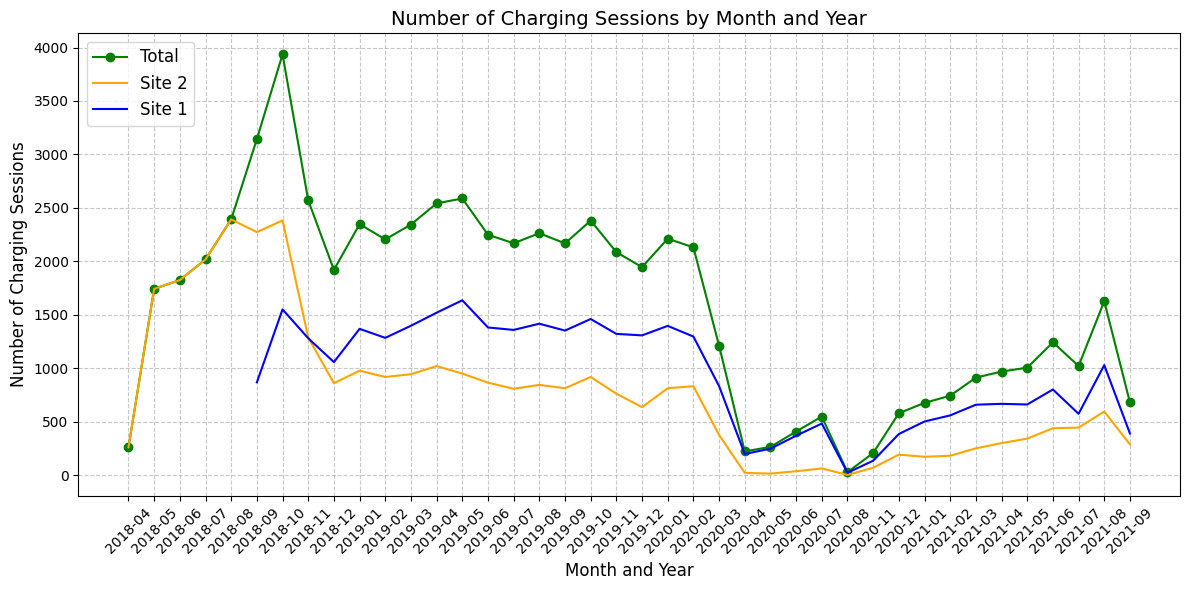

In [12]:
data_charge["month_year"] = data_charge["connectionTime"].dt.to_period("M")
charging_by_month_year = data_charge["month_year"].value_counts().sort_index()
charging_by_month_year_2 = data_charge[data_charge["siteID"]==2]["month_year"].value_counts().sort_index()
charging_by_month_year_1 = data_charge[data_charge["siteID"]==1]["month_year"].value_counts().sort_index()


# plot
plt.figure(figsize=(12, 6))
plt.plot(
    charging_by_month_year.index.astype(str),
    charging_by_month_year.values,
    marker="o",
    color="g",
    label="Total"
)
plt.plot(
    charging_by_month_year_2.index.astype(str),
    charging_by_month_year_2.values,
    color="orange",
    label="Site 2"
)
plt.plot(
    charging_by_month_year_1.index.astype(str),
    charging_by_month_year_1.values,
    color="b",
    label="Site 1"
)
plt.title("Number of Charging Sessions by Month and Year", fontsize=14)
plt.xlabel("Month and Year", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(loc="upper left", fontsize=12)
plt.tight_layout()
plt.show()


We can see that the start of the charging session recording is in April 2018 and ends in September 2021, which is why not every month occurs equally often and we therefore have to normalise. We also see a gap between 08/2020 and 11/2020.

C:\Users\Reintjes\AppData\Local\Temp\ipykernel_15304\1015995705.py:38: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2790.6666666666665' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  normalized_charging_by_season_site.loc[season] = (
C:\Users\Reintjes\AppData\Local\Temp\ipykernel_15304\1015995705.py:38: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2081.3333333333335' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  normalized_charging_by_season_site.loc[season] = (


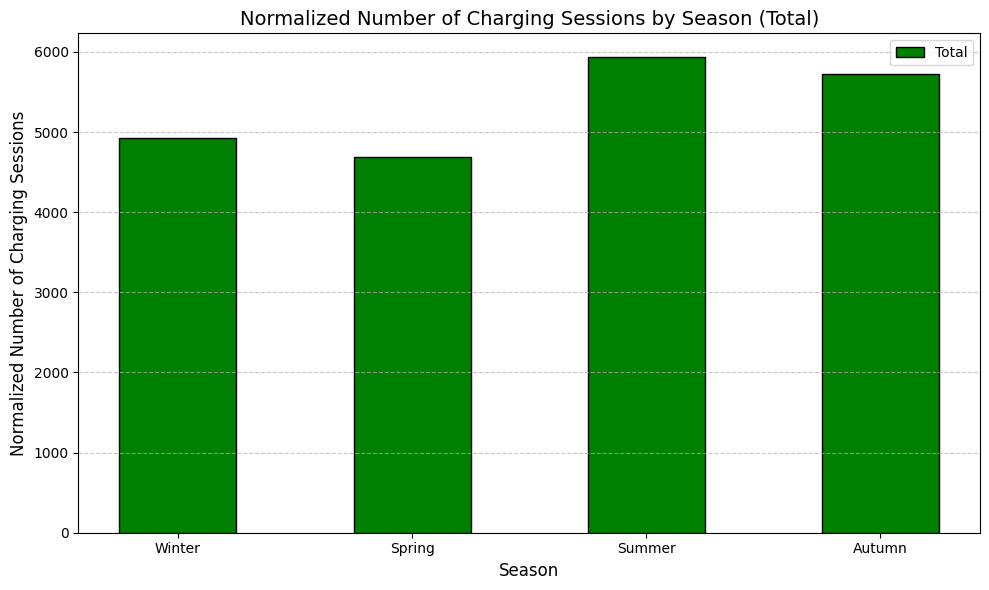

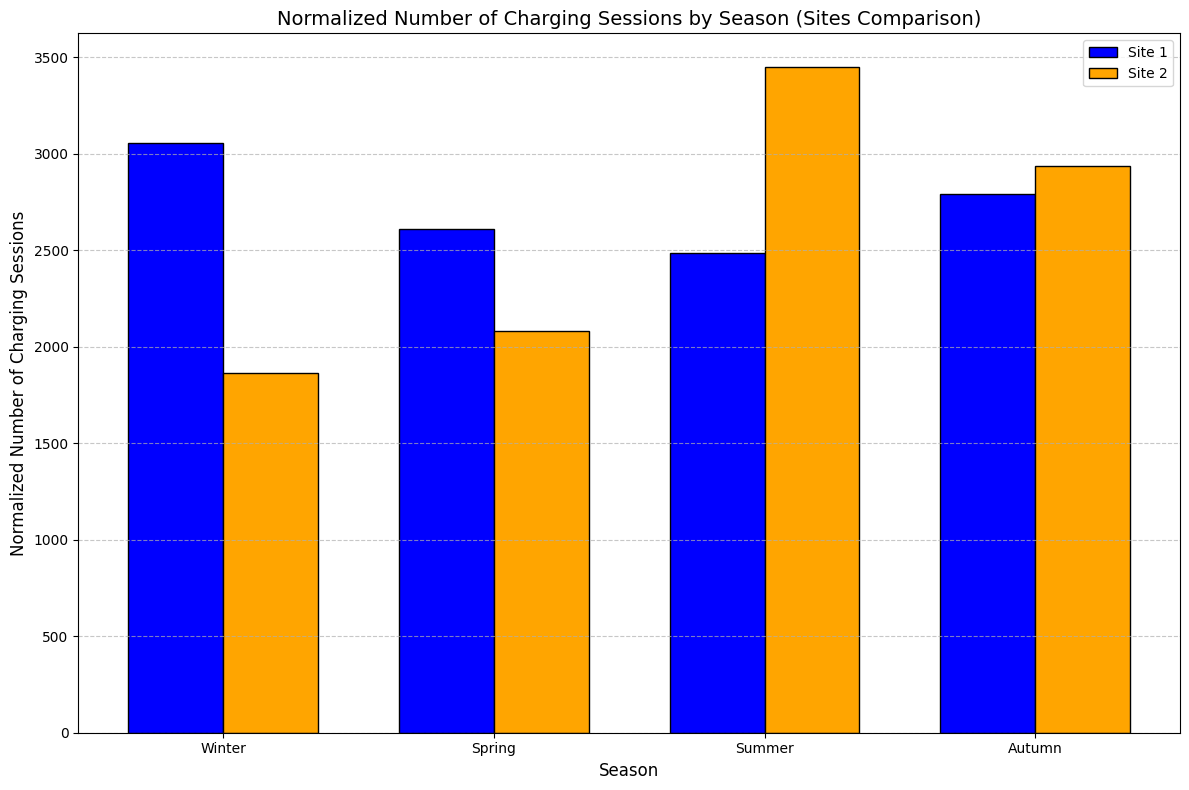

In [13]:
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"

data_charge["season"] = data_charge["connectionTime"].apply(get_season)

season_month_count = {
    "Winter": len(
        data_charge[data_charge["season"] == "Winter"]["connectionTime"].dt.month.unique()
    ),
    "Spring": len(
        data_charge[data_charge["season"] == "Spring"]["connectionTime"].dt.month.unique()
    ),
    "Summer": len(
        data_charge[data_charge["season"] == "Summer"]["connectionTime"].dt.month.unique()
    ),
    "Autumn": len(
        data_charge[data_charge["season"] == "Autumn"]["connectionTime"].dt.month.unique()
    ),
}

charging_by_season = data_charge["season"].value_counts()
normalized_charging_by_season = charging_by_season / [
    season_month_count[season] for season in charging_by_season.index
]

charging_by_season_site = data_charge.groupby(["season", "siteID"]).size().unstack(fill_value=0)

normalized_charging_by_season_site = charging_by_season_site.copy()
for season in charging_by_season_site.index:
    normalized_charging_by_season_site.loc[season] = (
        charging_by_season_site.loc[season] / season_month_count[season]
    )

season_order = ["Winter", "Spring", "Summer", "Autumn"]
normalized_charging_by_season = normalized_charging_by_season.reindex(season_order)
normalized_charging_by_season_site = normalized_charging_by_season_site.reindex(season_order)

plt.figure(figsize=(10, 6))
x = np.arange(len(season_order))  
plt.bar(
    x,
    normalized_charging_by_season.values,
    color="green",
    width=0.5,
    label="Total",
    edgecolor="black",
)
plt.title("Normalized Number of Charging Sessions by Season (Total)", fontsize=14)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Normalized Number of Charging Sessions", fontsize=12)
plt.xticks(x, season_order)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/season_total.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 8))
width = 0.35  
plt.bar(
    x - width / 2,
    normalized_charging_by_season_site[1],
    width=width,
    label="Site 1",
    color="blue",
    edgecolor="black",
)
plt.bar(
    x + width / 2,
    normalized_charging_by_season_site[2],
    width=width,
    label="Site 2",
    color="orange",
    edgecolor="black",
)
plt.title("Normalized Number of Charging Sessions by Season (Sites Comparison)", fontsize=14)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Normalized Number of Charging Sessions", fontsize=12)
plt.xticks(x, season_order)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("../figures/season_sites_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


**Seasonal patterns observed and explaination:** Charging activity by season shows only slight differences, with summer showing the highest normalized number of charging events, followed by autumn, winter and finally spring. The highest charging activity in summer could be explained by longer daytimes and more intensive use of vehicles, such as vacation trips or other leisure activities.

## KPIs
**Task** Key Performance Indicators (KPIs): Define three time-dependent KPIs that you would include in a dashboard for the hub operator. These KPIs must provide an immediate overview of the current hub operation and how it is doing in terms of utilization or other business-related aspects. Briefly explain the rationale behind selecting each KPI, explain why you have chosen it and, where needed, provide references. **Calculate hourly values for the selected KPIs and visualize them over time. Which trends do you observe?** How do you explain them?

We have chosen the following three KPIs: **kWh Delivered, Utilization Rate and Charge Time Ratio**.

The **kWh Delivered** KPI measures the total energy charged (∑kWh) and serves as a proxy for both the operator's revenue and the CO₂ emissions saved. Helmus and van den Hoed (2016) emphasize that the energy charged is an important indicator to assess the operation and sustainability goals of the infrastructure, as each kilowatt hour charged can be translated into kilometers driven and thus emissions avoided.

The **utilization rate** indicates how often the charging stations are used compared to their availability. Helmus and van den Hoed (2016) emphasize that the utilization rate is an essential KPI for measuring usage efficiency and identifying over- or under-capacity. This KPI enables operators to analyze periods of high or low utilization and take appropriate action, such as expanding capacity or adjusting pricing models.

The **KPI Charge Time Ratio** (charging time / connection time) evaluates the efficiency of charging station usage. A high charging time in relation to the connection time shows that the infrastructure is being used efficiently, while a low ratio indicates blockages caused by parked vehicles that are not charging. Helmus and van den Hoed (2016) explicitly mention this ratio as an important KPI, as it directly influences the accessibility and efficiency of the charging infrastructure and enables operators to achieve improvements through targeted measures such as penalties or incentives

Source: @article{article,
author = {Helmus, Jurjen and van den Hoed, Robert},
year = {2016},
month = {12},
pages = {733-741},
title = {Key Performance Indicators of Charging infrastructure},
volume = {8},
journal = {World Electric Vehicle Journal},
doi = {10.3390/wevj8040733}
}

### 1. kWh Delivered (per hour)

In [14]:
df_kWh = data_charge

In [15]:
# Function to distribute kWh over hours
def calc_kwh(row):
    start = row['connectionTime']
    end = row['endChargingTime']
    total_kwh = row['kWhDelivered']

    # Skip entries where the start and end time are the same to avoid ZeroDivisionError
    if start == end:
        return
    
    # Create a range of hours between the start and end time
    hours = pd.date_range(start.floor('H'), end.ceil('H'), freq='H')
    
    # Calculate the kWh for each hour
    kwh_distribution = []
    for i in range(len(hours) - 1):
        current_hour_start = hours[i]
        next_hour_start = hours[i + 1]
        
        if next_hour_start > end:
            next_hour_start = end
            
        # Since we initilize current_hour_start as hours[i] in each iteration, we have to set it to the start value to calculate the first hour correct
        if current_hour_start < start:
            current_hour_start = start
            
        hour_duration = (next_hour_start - current_hour_start).total_seconds() / 3600

        if hour_duration == 0:
            continue
        
        kwh_for_hour = (hour_duration / ((end - start).total_seconds() / 3600)) * total_kwh
        kwh_distribution.append((current_hour_start.floor('H'), kwh_for_hour))
    
    return kwh_distribution

# Apply the function to each row
kwh_distributions = df_kWh.apply(calc_kwh, axis=1)

# Parse the data needed due to our special data format, returned by the applied function
flattened_kwh_distributions = [item for sublist in kwh_distributions if sublist is not None for item in sublist]
distribution_df = pd.DataFrame(flattened_kwh_distributions, columns=['DateHourly', 'kWh'])

# Sum the kWh for each DateHourly
hourly_kwh = distribution_df.groupby('DateHourly')['kWh'].sum().reset_index()

<Axes: title={'center': 'Hourly Values for the kWh Delivered (per hour) of the Two Sides'}, xlabel='DateHourly'>

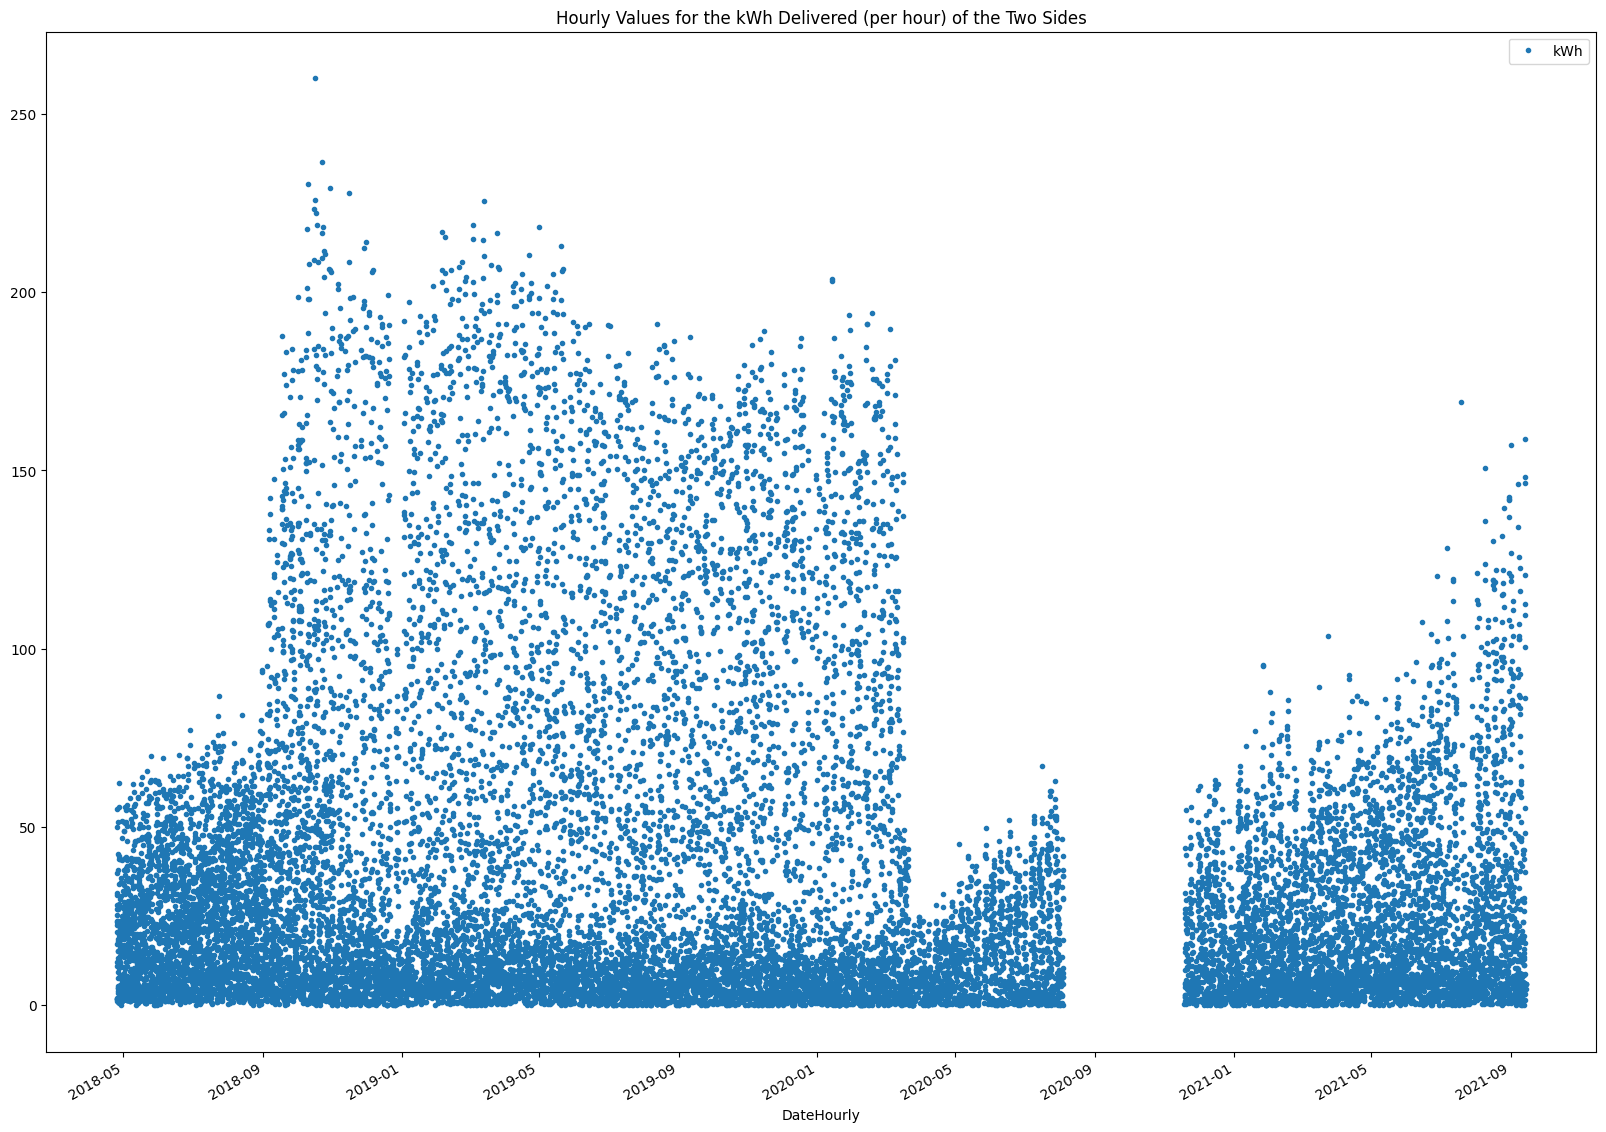

In [16]:
hourly_kwh.set_index("DateHourly").plot(style=".", figsize=(20, 15,), title="Hourly Values for the kWh Delivered (per hour) of the Two Sides")

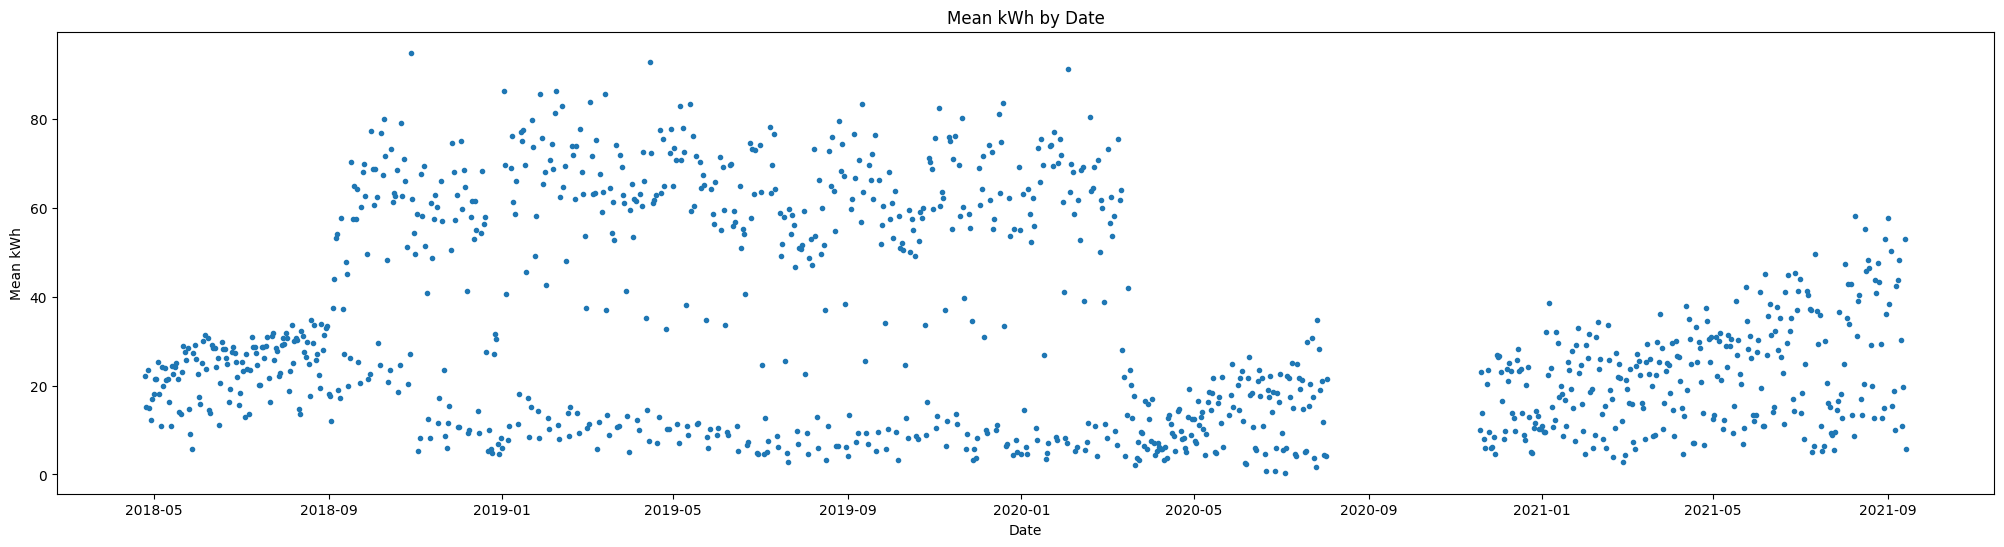

In [17]:
# Create a new column for the date
hourly_kwh['Date'] = hourly_kwh['DateHourly'].dt.date

# Calculate the mean kWh for each hour of the day across all years
mean_kwh_by_day = hourly_kwh.groupby('Date')['kWh'].mean()

# Plot the results
plt.figure(figsize=(25, 6))
mean_kwh_by_day.plot(style=".")
plt.xlabel('Date')
plt.ylabel('Mean kWh')
plt.title('Mean kWh by Date')
plt.show()

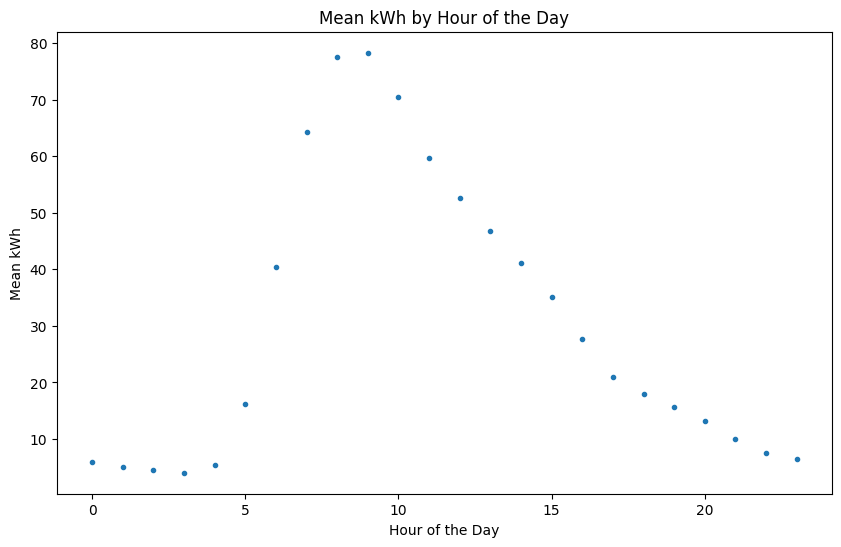

In [18]:
# Create a new column for the hour of the day
hourly_kwh['Hour'] = hourly_kwh['DateHourly'].dt.hour

# Calculate the mean kWh for each hour of the day across all years
mean_kwh_by_hour = hourly_kwh.groupby('Hour')['kWh'].mean()

# Plot the results
plt.figure(figsize=(10, 6))
mean_kwh_by_hour.plot(style=".")
plt.xlabel('Hour of the Day')
plt.ylabel('Mean kWh')
plt.title('Mean kWh by Hour of the Day')
plt.show()

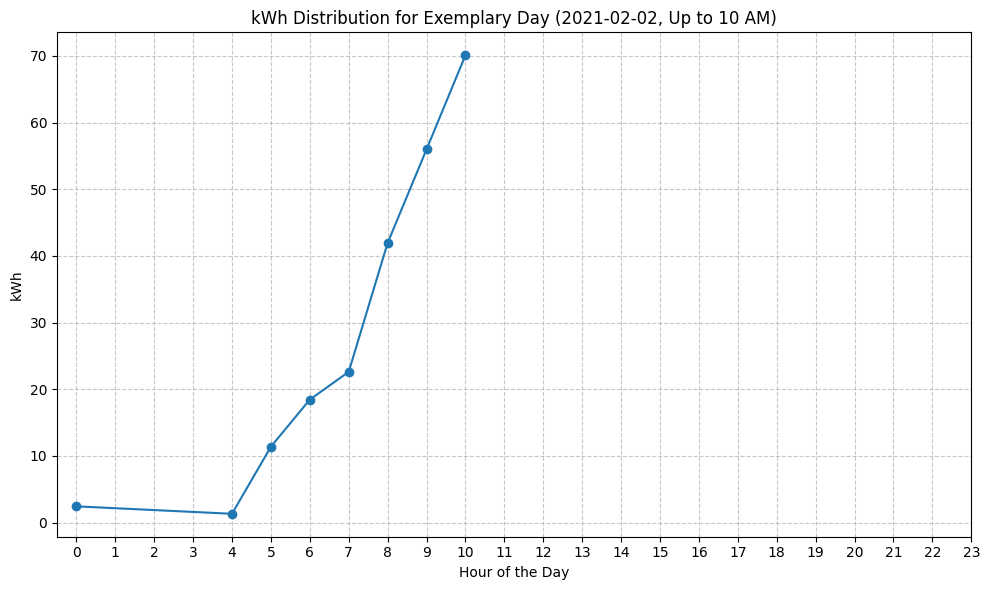

In [19]:
# Filter data for a specific day (e.g., 2021-02-02) and up to 10 AM
cutoff_hour = 10
example_day = hourly_kwh[
    (hourly_kwh['DateHourly'].dt.date == pd.Timestamp('2021-02-02').date()) &
    (hourly_kwh['Hour'] <= cutoff_hour)
]

# Plot the kWh distribution for the specific day up to 10 AM
plt.figure(figsize=(10, 6))
plt.plot(example_day['Hour'], example_day['kWh'], marker="o", linestyle="-")
plt.xlabel('Hour of the Day')
plt.ylabel('kWh')
plt.title('kWh Distribution for Exemplary Day (2021-02-02, Up to 10 AM)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


### 2. Utilization rate (per hour)

In [20]:
df_util = data_charge

In [21]:
# Function to distribute kWh over hours
def calc_util(row):
    start = row['connectionTime']
    end = row['disconnectTime']

    # Skip entries where the start and end time are the same to avoid ZeroDivisionError
    if start == end:
        return
    
    # Create a range of hours between the start and end time
    hours = pd.date_range(start.floor('H'), end.ceil('H'), freq='H')
    
    # Calculate the kWh for each hour
    util_distribution = []
    for i in range(len(hours) - 1):
        current_hour_start = hours[i]
        next_hour_start = hours[i + 1]
        
        if next_hour_start > end:
            next_hour_start = end
        
        # Since we initilize current_hour_start as hours[i] in each iteration, we have to set it to the start value to calculate the first hour correct
        if current_hour_start < start:
            current_hour_start = start
            
        util_for_hour = (next_hour_start - current_hour_start).total_seconds() / 3600
        if util_for_hour == 0:
            continue
        
        util_distribution.append((current_hour_start.floor('H'), util_for_hour))
    
    return util_distribution

# Apply the function to each row and create a DataFrame
util_dist = df_util.apply(calc_util, axis=1)

# Parse the data needed due to our special data format, returned by the applied function
flattened_util_distributions = [item for sublist in util_dist if sublist is not None for item in sublist]
distribution_df = pd.DataFrame(flattened_util_distributions, columns=['DateHourly', 'Utilization'])

# Sum the kWh for each DateHourly
hourly_util = distribution_df.groupby('DateHourly')['Utilization'].sum().reset_index()

# Devide the summed utilization by the amount uf charging spaces to normalize the data
hourly_util["Utilization"] = hourly_util["Utilization"]/(data_charge.spaceID.unique().__len__())

<Axes: title={'center': 'Hourly Values for the Utilization (per hour) of the Two Sides'}, xlabel='DateHourly'>

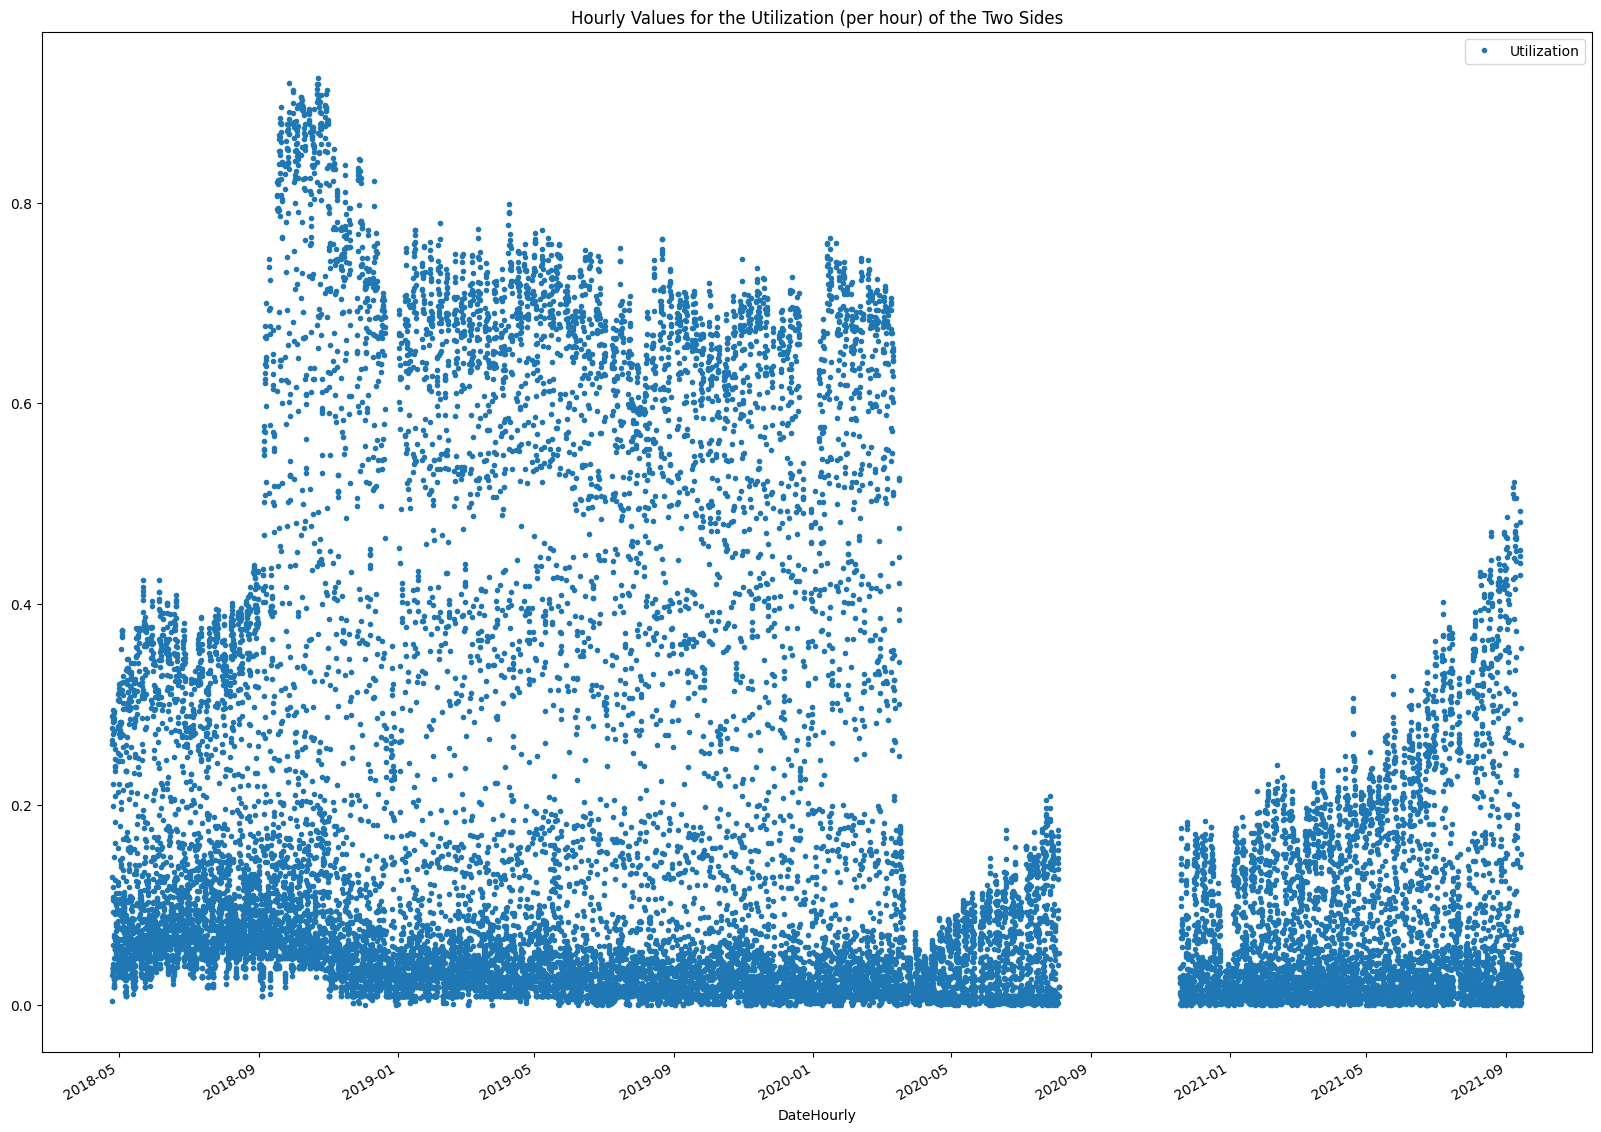

In [22]:
hourly_util.set_index("DateHourly").plot(style=".", figsize=(20, 15,), title="Hourly Values for the Utilization (per hour) of the Two Sides")

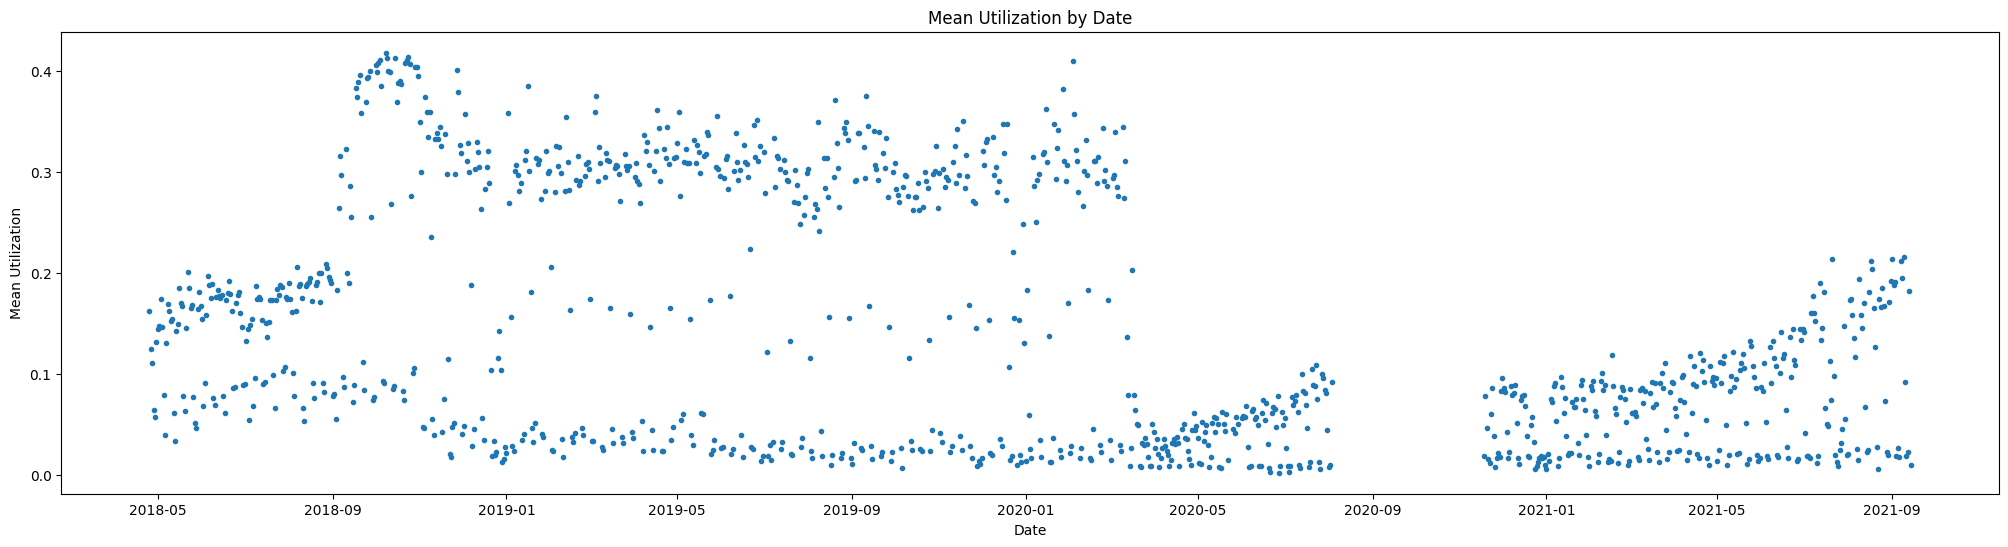

In [23]:
# Create a new column for the hour of the day
hourly_util['Date'] = hourly_util['DateHourly'].dt.date
mean_util_by_day = hourly_util.groupby('Date')['Utilization'].mean()

# Plot the results
plt.figure(figsize=(25, 6))
mean_util_by_day.plot(style=".")
plt.xlabel('Date')
plt.ylabel('Mean Utilization')
plt.title('Mean Utilization by Date')
plt.show()

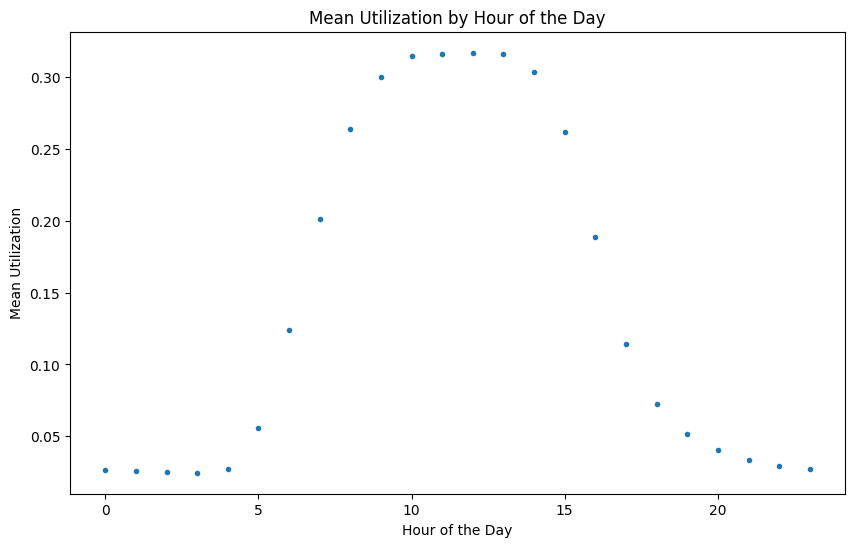

In [24]:
# Create a new column for the hour of the day
hourly_util['Hour'] = hourly_util['DateHourly'].dt.hour 

# Calculate the mean kWh for each hour of the day across all years
mean_util_by_hour = hourly_util.groupby('Hour')['Utilization'].mean()

# Plot the results
plt.figure(figsize=(10, 6))
mean_util_by_hour.plot(style=".")
plt.xlabel('Hour of the Day')
plt.ylabel('Mean Utilization')
plt.title('Mean Utilization by Hour of the Day')
plt.show()

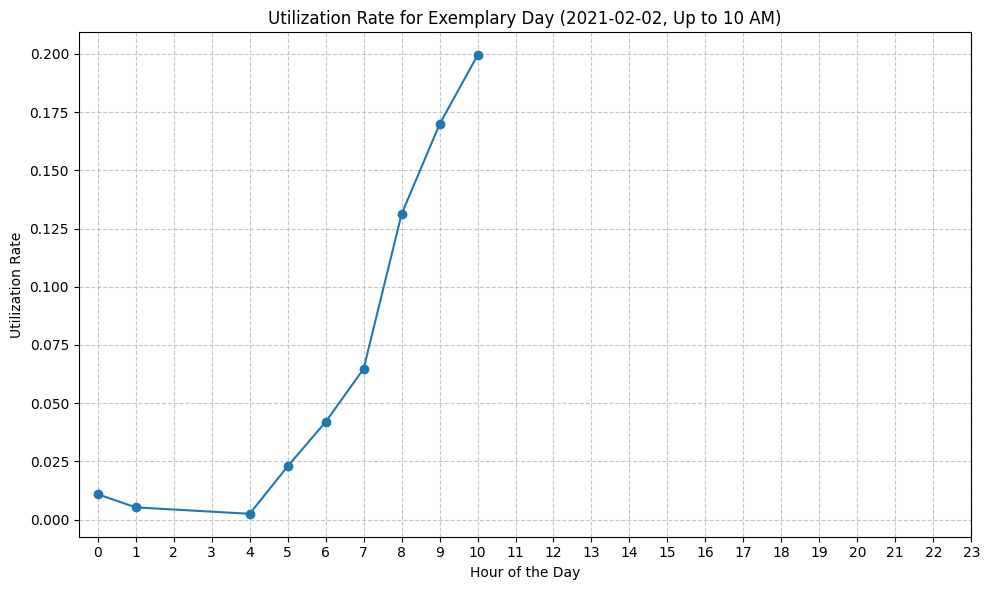

In [25]:
hourly_util['Hour'] = hourly_util['DateHourly'].dt.hour 
# Filter data for a specific day (e.g., 2021-02-02) and up to 10 AM
cutoff_hour = 10
example_day_util = hourly_util[
    (hourly_util['DateHourly'].dt.date == pd.Timestamp('2021-02-02').date()) &
    (hourly_util['Hour'] <= cutoff_hour)
]

# Plot the utilization rate for the specific day up to 10 AM
plt.figure(figsize=(10, 6))
plt.plot(example_day_util['Hour'], example_day_util['Utilization'], marker="o", linestyle="-")
plt.xlabel('Hour of the Day')
plt.ylabel('Utilization Rate')
plt.title('Utilization Rate for Exemplary Day (2021-02-02, Up to 10 AM)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


### 3. Charge time ration (per hour)

In [26]:
# Function to calculate the charging and blocking ratio for each hour "Charge Time Ratio" (CTR)
df_chargetime = data_charge

def calculate_ctr(row):
    start = row['connectionTime']
    end = row['endChargingTime']
    disconnect = row['disconnectTime']
    
    hours = pd.date_range(start.floor('H'), disconnect.ceil('H'), freq='H')
    ratios = []

    for i in range(len(hours) - 1):
        current_hour_start = hours[i]
        next_hour_start = hours[i + 1]
        
        if next_hour_start > disconnect:
            next_hour_start = disconnect
        
        # Since we initilize current_hour_start as hours[i] in each iteration, we have to set it to the start value to calculate the first hour correct
        if current_hour_start < start:
            current_hour_start = start
        
        charging_duration = min(end, next_hour_start) - current_hour_start
        charging_ratio = (charging_duration.total_seconds() / 3600)

        # To avoid negative charging_ratio for time period after the charging ended we parse it this way:
        charging_ratio = max(0, charging_ratio)

        blocking_duration = min(disconnect, next_hour_start) - current_hour_start
        blocking_ratio = blocking_duration.total_seconds() / 3600
        
        ratios.append((current_hour_start.floor('H'), charging_ratio, blocking_ratio))
    
    return ratios

# Apply the function to each row and create a DataFrame
ratios = df_chargetime.apply(calculate_ctr, axis=1)

# Parse the data needed due to our special data format
flattened_ratios = [item for sublist in ratios if sublist is not None for item in sublist]
ratio_df = pd.DataFrame(flattened_ratios, columns=['DateHourly', 'ChargingRatio', 'BlockingRatio'])

# Sum the ChargingRatios and BlockingRatios for each DateHourly
hourly_charge_ratios = ratio_df.groupby(['DateHourly']).agg({'ChargingRatio': 'sum', 'BlockingRatio': 'sum'}).reset_index()

# Fix the column names
hourly_charge_ratios.rename(columns={'ChargingRatio': 'TotalChargingRatio', 'BlockingRatio': 'TotalBlockingRatio'}, inplace=True)

# Calculate the ChargeTimeRatio
hourly_charge_ratios["ChargeTimeRatio"] = hourly_charge_ratios["TotalChargingRatio"] / hourly_charge_ratios["TotalBlockingRatio"]

<Axes: title={'center': 'Hourly Values for the Charge Time Ratio (per hour) of the Two Sides'}, xlabel='DateHourly'>

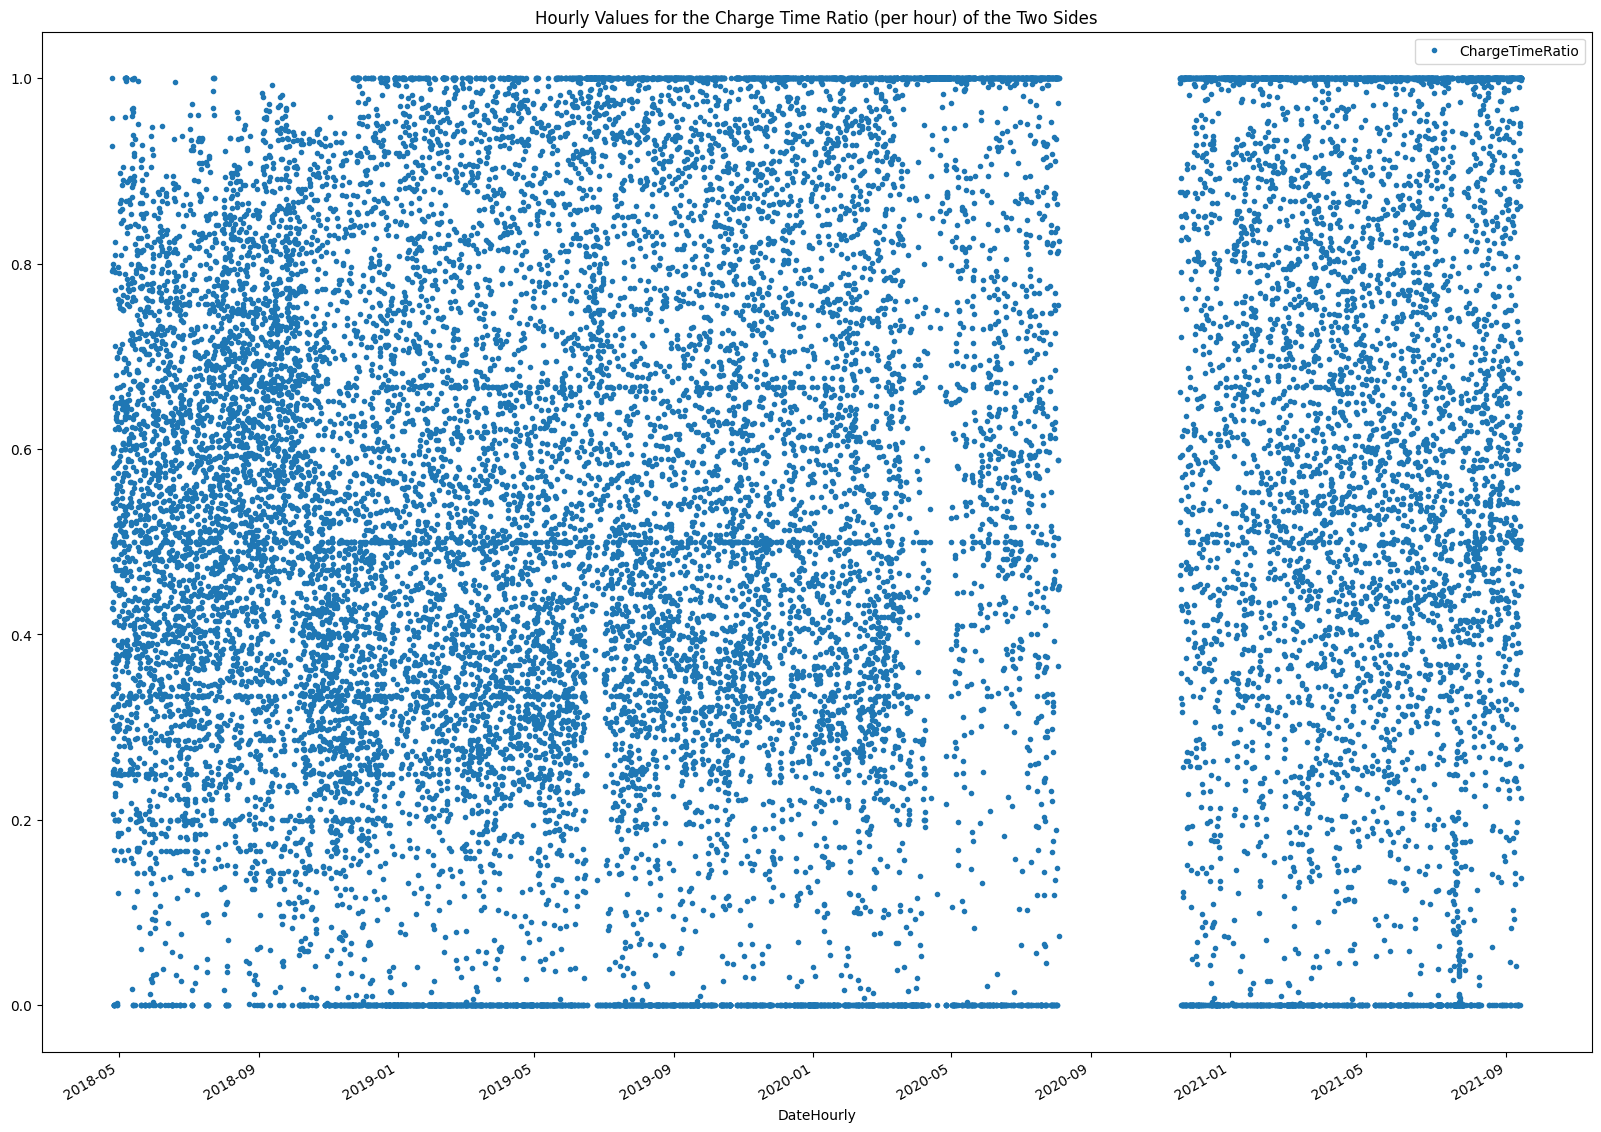

In [27]:
hourly_charge_ratios.set_index("DateHourly")[["ChargeTimeRatio"]].plot(style=".", figsize=(20, 15,), title="Hourly Values for the Charge Time Ratio (per hour) of the Two Sides")

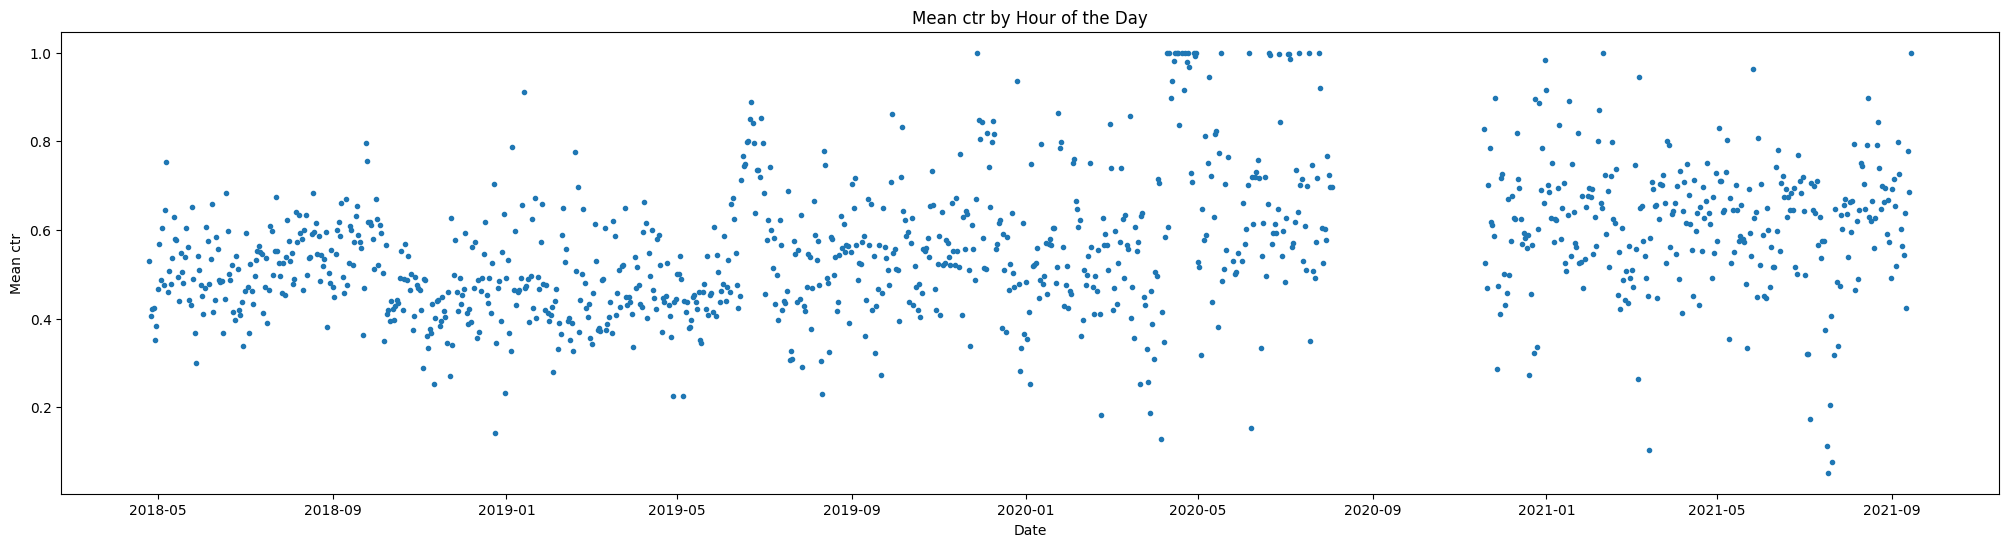

In [28]:
# Create a new column for the hour of the day
hourly_charge_ratios["Date"] = hourly_charge_ratios["DateHourly"].dt.date

# Calculate the mean ctr for each hour of the day across all years
mean_ctr_by_day = hourly_charge_ratios.groupby('Date')['ChargeTimeRatio'].mean()

# Plot the results
plt.figure(figsize=(25, 6))
mean_ctr_by_day.plot(style=".")

plt.xlabel('Date')
plt.ylabel('Mean ctr')
plt.title('Mean ctr by Hour of the Day')
plt.show()

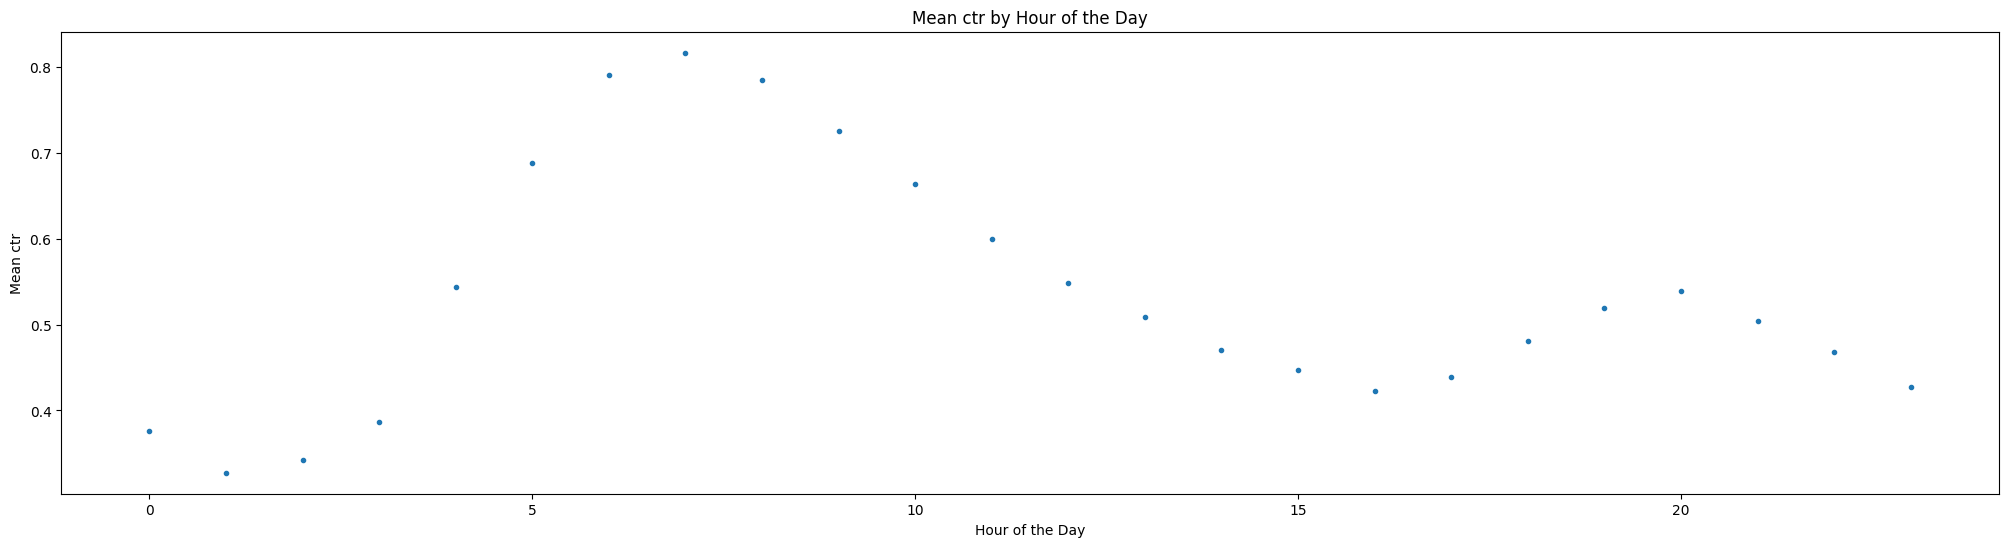

In [29]:
# Create a new column for the hour of the day
hourly_charge_ratios["Hour"] = hourly_charge_ratios["DateHourly"].dt.hour

# Calculate the mean kWh for each hour of the day across all years
mean_ctr_by_day = hourly_charge_ratios.groupby('Hour')['ChargeTimeRatio'].mean()

# Plot the results
plt.figure(figsize=(25, 6))
mean_ctr_by_day.plot(style=".")
plt.xlabel('Hour of the Day')
plt.ylabel('Mean ctr')
plt.title('Mean ctr by Hour of the Day')
plt.show()

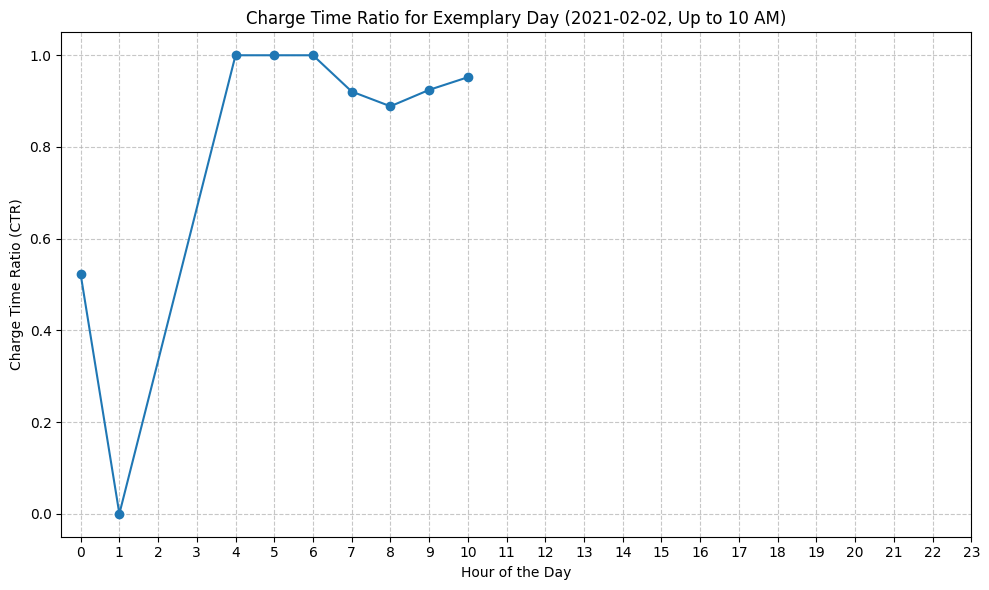

In [30]:
hourly_charge_ratios["Hour"] = hourly_charge_ratios["DateHourly"].dt.hour
# Filter data for a specific day (e.g., 2021-02-02) and up to 10 AM
cutoff_hour = 10
example_day_ctr = hourly_charge_ratios[
    (hourly_charge_ratios['DateHourly'].dt.date == pd.Timestamp('2021-02-02').date()) &
    (hourly_charge_ratios['Hour'] <= cutoff_hour)
]

# Plot the Charge Time Ratio for the specific day up to 10 AM
plt.figure(figsize=(10, 6))
plt.plot(example_day_ctr['Hour'], example_day_ctr['ChargeTimeRatio'], marker="o", linestyle="-")
plt.xlabel('Hour of the Day')
plt.ylabel('Charge Time Ratio (CTR)')
plt.title('Charge Time Ratio for Exemplary Day (2021-02-02, Up to 10 AM)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


#### Final Dashboard for an example day

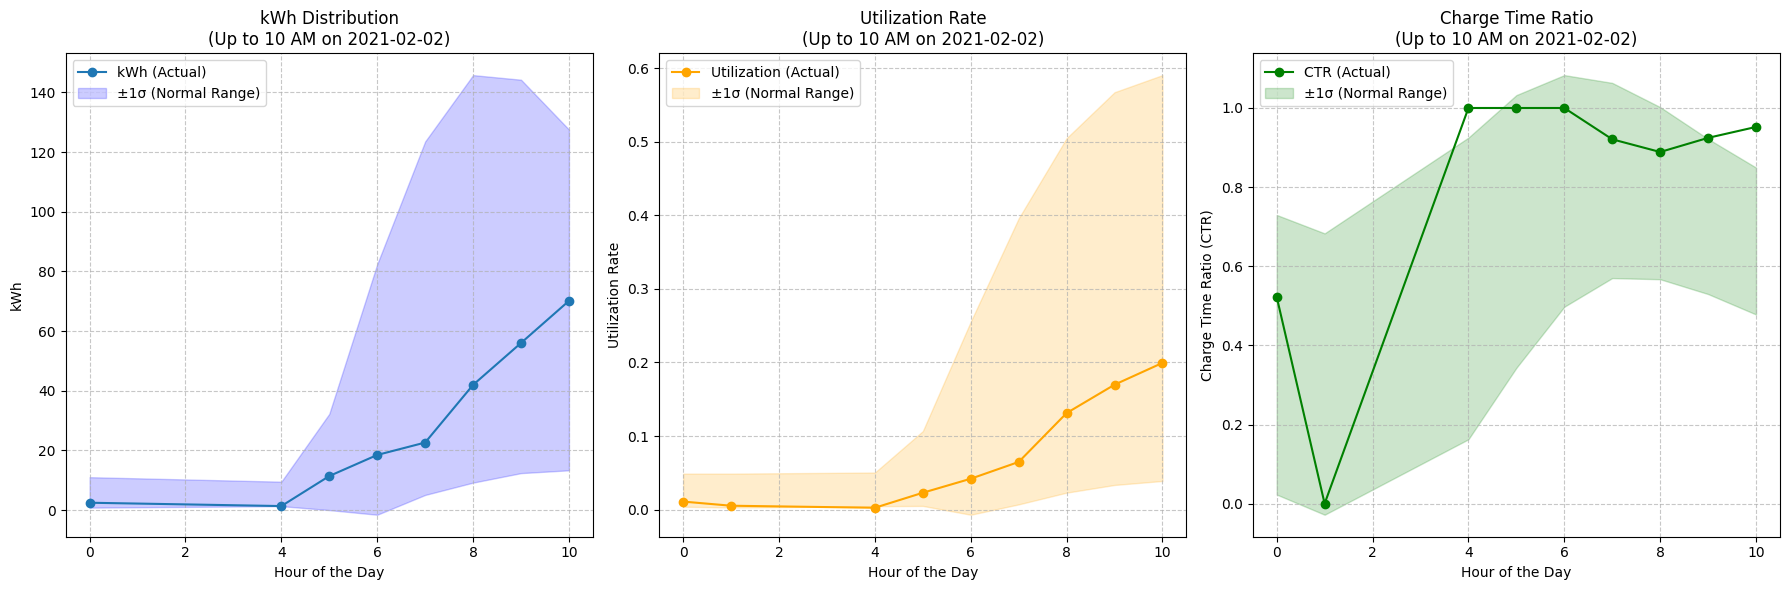

In [31]:

# Set cutoff hour
cutoff_hour = 10
specific_date = pd.Timestamp('2021-02-02').date()

# Filter data for kWh
example_day_kwh = hourly_kwh[
    (hourly_kwh['DateHourly'].dt.date == specific_date) &
    (hourly_kwh['Hour'] <= cutoff_hour)
]

# Filter data for Utilization Rate
example_day_util = hourly_util[
    (hourly_util['DateHourly'].dt.date == specific_date) &
    (hourly_util['Hour'] <= cutoff_hour)
]

# Filter data for Charge Time Ratio
example_day_ctr = hourly_charge_ratios[
    (hourly_charge_ratios['DateHourly'].dt.date == specific_date) &
    (hourly_charge_ratios['Hour'] <= cutoff_hour)
]

# Calculate Mean and Sigma (1σ for simplicity) for each KPI
kwh_mean = hourly_kwh.groupby('Hour')['kWh'].mean()
kwh_std = hourly_kwh.groupby('Hour')['kWh'].std()

util_mean = hourly_util.groupby('Hour')['Utilization'].mean()
util_std = hourly_util.groupby('Hour')['Utilization'].std()

ctr_mean = hourly_charge_ratios.groupby('Hour')['ChargeTimeRatio'].mean()
ctr_std = hourly_charge_ratios.groupby('Hour')['ChargeTimeRatio'].std()

# Create horizontal subplots
fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=False)

# Plot kWh Distribution with Sigma Bands
axs[0].plot(example_day_kwh['Hour'], example_day_kwh['kWh'], marker="o", linestyle="-", label="kWh (Actual)")
axs[0].fill_between(
    example_day_kwh['Hour'],
    kwh_mean[example_day_kwh['Hour']] - kwh_std[example_day_kwh['Hour']],
    kwh_mean[example_day_kwh['Hour']] + kwh_std[example_day_kwh['Hour']],
    color="blue",
    alpha=0.2,
    label="±1σ (Normal Range)"
)
axs[0].set_xlabel("Hour of the Day")
axs[0].set_ylabel("kWh")
axs[0].set_title(f"kWh Distribution\n(Up to {cutoff_hour} AM on {specific_date})")
axs[0].grid(True, linestyle="--", alpha=0.7)
axs[0].legend(loc="upper left")

# Plot Utilization Rate with Sigma Bands
axs[1].plot(example_day_util['Hour'], example_day_util['Utilization'], marker="o", linestyle="-", color="orange", label="Utilization (Actual)")
axs[1].fill_between(
    example_day_util['Hour'],
    util_mean[example_day_util['Hour']] - util_std[example_day_util['Hour']],
    util_mean[example_day_util['Hour']] + util_std[example_day_util['Hour']],
    color="orange",
    alpha=0.2,
    label="±1σ (Normal Range)"
)
axs[1].set_xlabel("Hour of the Day")
axs[1].set_ylabel("Utilization Rate")
axs[1].set_title(f"Utilization Rate\n(Up to {cutoff_hour} AM on {specific_date})")
axs[1].grid(True, linestyle="--", alpha=0.7)
axs[1].legend(loc="upper left")

# Plot Charge Time Ratio with Sigma Bands
axs[2].plot(example_day_ctr['Hour'], example_day_ctr['ChargeTimeRatio'], marker="o", linestyle="-", color="green", label="CTR (Actual)")
axs[2].fill_between(
    example_day_ctr['Hour'],
    ctr_mean[example_day_ctr['Hour']] - ctr_std[example_day_ctr['Hour']],
    ctr_mean[example_day_ctr['Hour']] + ctr_std[example_day_ctr['Hour']],
    color="green",
    alpha=0.2,
    label="±1σ (Normal Range)"
)
axs[2].set_xlabel("Hour of the Day")
axs[2].set_ylabel("Charge Time Ratio (CTR)")
axs[2].set_title(f"Charge Time Ratio\n(Up to {cutoff_hour} AM on {specific_date})")
axs[2].grid(True, linestyle="--", alpha=0.7)
axs[2].legend(loc="upper left")

# Adjust layout
plt.tight_layout()
plt.savefig("../figures/dashboard.png", dpi=300, bbox_inches="tight")
plt.show()


In [32]:
hourly_charge_ratios = hourly_charge_ratios[["DateHourly", "ChargeTimeRatio"]]
hourly_util = hourly_util[["DateHourly","Utilization"]]
hourly_kwh = hourly_kwh[["DateHourly","kWh"]]

In [33]:
df_kpis_hourly = hourly_kwh.merge(hourly_util, on='DateHourly').merge(hourly_charge_ratios, on='DateHourly')

In [34]:
df_kpis_hourly.to_pickle("../data/kpis_hourly.pkl")

## Site Identification
**Task**: Site Characteristics: The hub operator provided you with the data set, but has seemed to forget which site was supplying which data... Can you find out which of the two sites is the public one?
Try to combine data understanding from previous descriptive analytics with domain knowledge (business understanding) of how private vs. public charging hubs might differ in operation. Explain your line of thought!

### The following descriptions can be derived from the previous time patterns and the analysis of seasonality:
- Charging usage during the day is very different: at site 1, most EVs are connected around 6/7am, while at site 2 most connections start at 8/9am. At site 2, however, the peak connection time is not as high as at site 1, the connection time is much more spread throughout the day. In addition, the use of the charging station at night is more likely at site 2.
- During the week, the number of charging sessions at the individual sites also varies: while site 1 is used most frequently during the week and almost not at all at weekends, site 2 is in use throughout the week. Usage at the weekend is also lower, but not as strong as at site 1.
- Similar to usage during the day and week, there are also differences in usage by season: site 1 is used about equally throughout the year. Site 2, on the other hand, shows a more uneven distribution: it is used most of the time in summer, then in fall, then in spring and then in winter.


### Interpretation based on the Descriptions and Domain Knowledge: Which site is public and which is private?

#### 1st daytime usage pattern
- **Site 1:** Most connections start at 6/7am, indicating regular working hours. This indicates that the users are employees of a company who come to work early and charge their vehicles during working hours.
- **Site 2:** Connections start at 8/9am and are spread throughout the day, with additional usage at night. This suits a public site such as a university, which is used by both internal users (students and staff) and external people, e.g. for visits, events or as a general parking lot.

**Conclusion:**  
- **Site 1:** Private (company)  
- **Site 2:** Public (university)  

---

#### 2nd weekly usage pattern
- **Site 1:** High usage during the week, almost no usage at weekends. This corresponds to the typical use of a private site, as companies usually only operate on weekdays and are closed at weekends.
- **Site 2:** Usage is spread throughout the week, with a slight decrease at weekends. Universities also have activity at weekends (e.g. by students, external visitors or events), but to a lesser extent than during the week.

**Conclusion:**  
- **Site 1:** Private (companies)  
- **Site 2:** Public (university)  

---

#### 3. seasonal use
- **Site 1:** Consistent use throughout the year. This suits a private site, as the presence of a company's employees does not depend heavily on the time of year.
- **Site 2:** Usage fluctuates seasonally, with peaks in summer and a decline in winter. This fits with a public site such as a university, which is subject to seasonal fluctuations (semester times, vacations) and attracts more external visitors in summer, e.g. for events or leisure activities on campus.

**Conclusion:**  
- **Site 1:** Private (company)  
- **Site 2:** Public (university)  

---


To strengthen our conclusion, lets analyze the blocking Duration and the userIDs, too

        count        mean         std  min      median          max
siteID                                                             
1       32831  163.873996  179.629466  0.0  110.766667  4609.066667
2       31007  160.162731  274.178027  0.0   53.733333  9367.283333


<Figure size 1000x600 with 0 Axes>

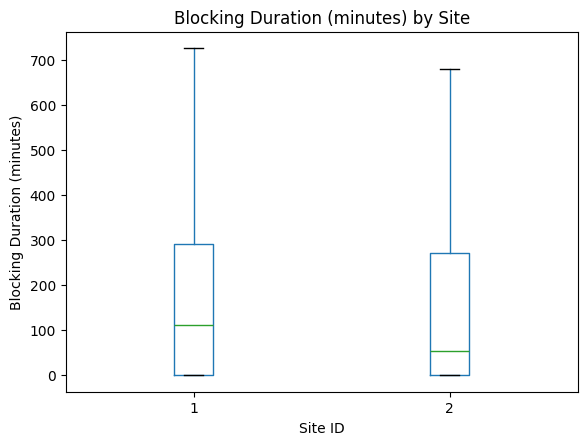

In [35]:
blocking_by_site = data_charge.groupby('siteID')['blockingDurationMin'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
#Describe the count, mean, std, min, median and max of the blockingDuration in Min of both sites
print(blocking_by_site)

# Visualize blockingDurationMin for each site
plt.figure(figsize=(10, 6))
data_charge.boxplot(column='blockingDurationMin', by='siteID', grid=False, showfliers=False)
plt.title('Blocking Duration (minutes) by Site')
plt.suptitle('')  
plt.xlabel('Site ID')
plt.ylabel('Blocking Duration (minutes)')
plt.show()

#### Median (typical blocking duration)

**Site 1**: 110.76 minutes - Typical for a private site where employees charge their vehicles for the duration of their work, which most of the time is longer than the charging time, resulting in a longer blocking duration time than at a public site.

**Site 2**: 53.53 minutes - The median is significantly lower. This could indicate many short-term uses by external persons or students who only charge for lectures or short stays, for example.

#### Distribution of blocking duration (standard deviation)

**Site 1**: 179.63 minutes - The dispersion is lower, which indicates more even loading times, typically for a fixed group of users (e.g. employees of a company).

**Site 2:** 273.03 minutes - The significantly higher dispersion indicates a public site with a mixed user base and variable loading behavior

#### Chargers, who have a UserID

In [36]:
charging_records_with_user = data_charge.groupby('siteID').apply(
    lambda group: group['userID'].notnull().sum()
)

total_records_per_site = data_charge.groupby('siteID').size()
percentage_with_user = (charging_records_with_user / total_records_per_site) * 100

result = pd.DataFrame({
    'Total Records': total_records_per_site,
    'Records with Users': charging_records_with_user,
    'Percentage with Users': percentage_with_user
}).reset_index()

print(result)


   siteID  Total Records  Records with Users  Percentage with Users
0       1          32831               30669              93.414760
1       2          31007               16227              52.333344


**Site 1** (93.41%):
A very high proportion of charging sessions have a registered user. This indicates controlled, registration-based use, as is typically the case at a private site (company) where the charging infrastructure is primarily used by employees.

**Site 2** (52.35%):
The proportion of charging sessions with a deposited user is significantly lower. This indicates less controlled or publicly accessible use, as might occur at a public site (university). Visitors or unregistered users could use the charging infrastructure here without being recorded as a specific user.

## Overall conclusion
The patterns in daily, weekly and seasonal use as well as the potential external use suggest that:  
- **Site 1** is the **private site** (company), as early peak times (6/7am), high weekday usage, minimal weekend activity, consistent year-round usage, longer blocking durations, and 93.41% registered users indicate controlled, employee-driven usage  
- **Site 2** is the **public site** (university), as spread-out connection times (8/9am), week-long usage, seasonal fluctuations, shorter blocking durations, and 52.35% registered users suggest diverse, public access.

